# Mathematical Modeling of the DRUPS System

This section describes the physical principles and equations used to simulate the kinetic energy transfer from the external rotor to the load.

## 1. System Kinematics

The system consists of a main shaft (stator and synchronous generator) rotating at a constant synchronous speed, and an external rotor (flywheel) that starts at a higher speed.

*   **Synchronous Angular Velocity ($\omega_s$):** Defined by the grid frequency ($f$) and the number of poles ($P$).
$$\omega_s = \frac{120 \cdot f}{P} \cdot \frac{2\pi}{60} \quad [\text{rad/s}]$$

*   **Slip Velocity ($\Delta\omega$):** The relative speed between the external rotor and the main shaft.
$$\Delta\omega(t) = \omega_r(t) - \omega_s \quad [\text{rad/s}]$$

## 2. Torque and Power Requirements

To sustain a constant electrical load ($P_{load}$) at the synchronous speed, the mechanical torque ($T_L$) that must be transferred through the electromagnetic coupling is:

$$T_L = \frac{P_{load}}{\omega_s} \quad [\text{N}\cdot\text{m}]$$

*Note: In this model, we assume the control system adjusts the DC injection current to maintain $T_L$ constant as the rotor decelerates.*

## 3. System Dynamics (Newton's Second Law)

The external rotor loses kinetic energy as it delivers torque to the shaft. Its deceleration is governed by the moment of inertia ($J_r$):

$$J_r \cdot \frac{d\omega_r}{dt} = -T_L$$

Solving this differential equation for a constant torque, we obtain the velocity of the rotor over time:

$$\omega_r(t) = \omega_{r0} - \left( \frac{T_L}{J_r} \right) \cdot t \quad [\text{rad/s}]$$

## 4. Energy Analysis

### 4.1. Available Kinetic Energy
The useful energy is not the total kinetic energy of the rotor, but the energy available **above** the synchronous speed threshold:

$$E_{available}(t) = \frac{1}{2} J_r \left( \omega_r(t)^2 - \omega_s^2 \right) \quad [\text{J}]$$

### 4.2. Power Flow and Heat Dissipation
The total power extracted from the inertia ($P_{total}$) is split into useful power delivered to the load and power dissipated as heat due to magnetic slip:

1.  **Useful Power:** $P_{useful} = T_L \cdot \omega_s = 5 \text{ MW}$ (Constant)
2.  **Dissipated Power (Slip Heat):** $P_{heat}(t) = T_L \cdot (\omega_r(t) - \omega_s) \quad [\text{W}]$

## 5. Coupling Efficiency

The mechanical efficiency ($\eta$) of the electromagnetic coupling is the ratio between the power delivered to the shaft and the total power extracted from the rotor:

$$\eta(t) = \frac{P_{useful}}{P_{total}(t)} = \frac{T_L \cdot \omega_s}{T_L \cdot \omega_r(t)} = \frac{\omega_s}{\omega_r(t)}$$

*Observation: Efficiency increases as the rotor speed approaches the synchronous speed, reaching 100% at the limit of operation (where $\Delta\omega = 0$).*

# DRUPS System Simulation (Diesel Rotary UPS) - 5 MW

This notebook presents the mathematical modeling and simulation of a kinetic energy storage system for 5 MW critical backup. The system utilizes an induction motor with an external rotor acting as a variable electromagnetic coupling (Eddy Current Coupling).

**Configuration:**
*   **Power:** 5 MW
*   **Voltage:** 400 V / 60 Hz
*   **Target Autonomy:** 30 seconds

---

## 1. System Parameters

Defining physical constants and design objectives.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Electrical and Mechanical Parameters
P_load = 5e6           # 5 MW
freq = 60              # Hz
poles = 4
V_nom = 400            # Volts

# Synchronous Speed (Load Shaft)
omega_s = (120 * freq / poles) * (2 * np.pi / 60)
torque_req = P_load / omega_s

# Inertia Parameters (External Rotor)
Jr = 15000             # kg.m^2
omega_r0 = 3000 * (2 * np.pi / 60) # Initial RPM

print(f"Required Torque: {torque_req:.1f} Nm")
print(f"Estimated Nominal Current (PF=0.8): {P_load/(np.sqrt(3)*V_nom*0.8):.0f} A")

Required Torque: 26525.8 Nm
Estimated Nominal Current (PF=0.8): 9021 A


## 2. Discharge Dynamics Simulation

Calculating the deceleration of the external rotor while delivering constant torque to the main shaft.

In [8]:
t = np.linspace(0, 60, 600)
omega_r = omega_r0 - (torque_req / Jr) * t

# Filter only the useful period (while omega_r > omega_s)
mask = omega_r >= omega_s
t_sim = t[mask]
omega_r_sim = omega_r[mask]

# Energy and Heat Calculations
energy_avail = 0.5 * Jr * (omega_r_sim**2 - omega_s**2)
p_heat = torque_req * (omega_r_sim - omega_s)
efficiency = (omega_s / omega_r_sim) * 100


## 3. Results Visualization

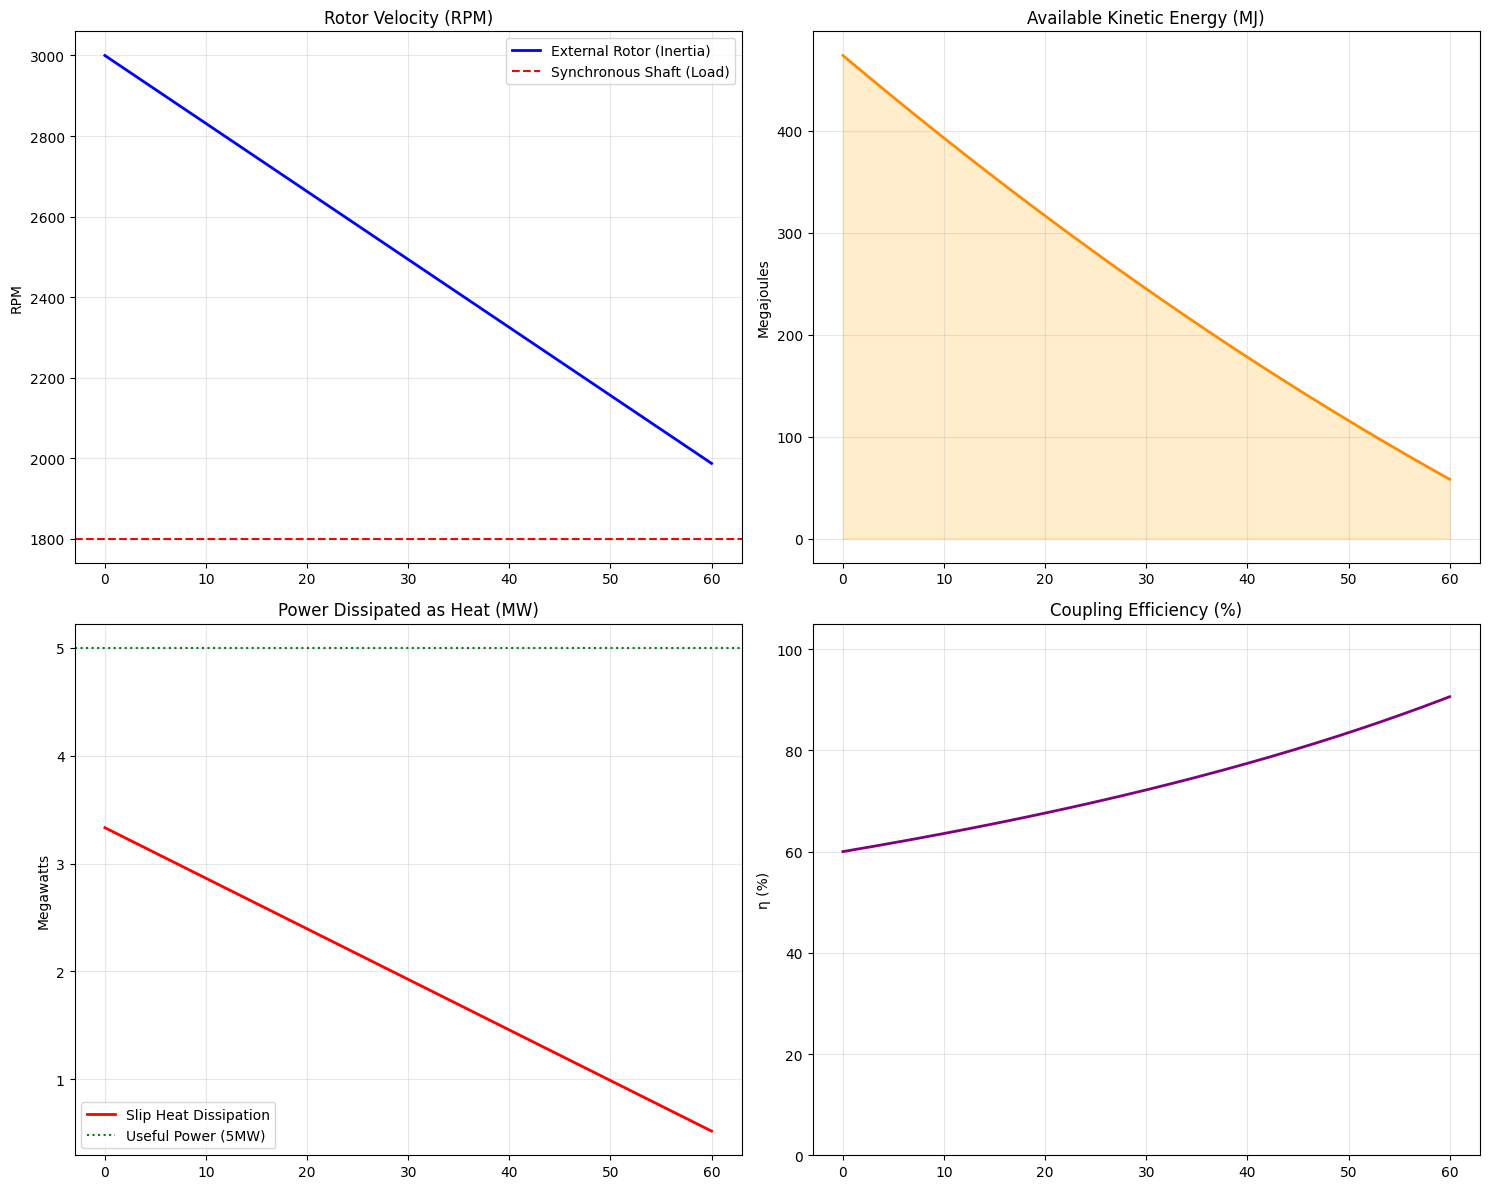

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12))

# 1. Velocity
axs[0, 0].plot(t_sim, omega_r_sim * 60 / (2*np.pi), label='External Rotor (Inertia)', color='blue', lw=2)
axs[0, 0].axhline(y=1800, color='red', linestyle='--', label='Synchronous Shaft (Load)')
axs[0, 0].set_title("Rotor Velocity (RPM)")
axs[0, 0].set_ylabel("RPM")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# 2. Available Energy
axs[0, 1].fill_between(t_sim, energy_avail / 1e6, color='orange', alpha=0.2)
axs[0, 1].plot(t_sim, energy_avail / 1e6, color='darkorange', lw=2)
axs[0, 1].set_title("Available Kinetic Energy (MJ)")
axs[0, 1].set_ylabel("Megajoules")
axs[0, 1].grid(True, alpha=0.3)

# 3. Dissipated Power (Heat)
axs[1, 0].plot(t_sim, p_heat / 1e6, color='red', lw=2, label='Slip Heat Dissipation')
axs[1, 0].axhline(y=5, color='green', linestyle=':', label='Useful Power (5MW)')
axs[1, 0].set_title("Power Dissipated as Heat (MW)")
axs[1, 0].set_ylabel("Megawatts")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# 4. Efficiency
axs[1, 1].plot(t_sim, efficiency, color='purple', lw=2)
axs[1, 1].set_title("Coupling Efficiency (%)")
axs[1, 1].set_ylabel("η (%)")
axs[1, 1].set_ylim(0, 105)
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Engineering Conclusions

1.  **Autonomy:** The system sustains 5 MW for approximately 40 seconds before reaching synchronism.
2.  **Thermal Stress:** The initial dissipation of **3.9 MW** requires a robust thermal design for the external rotor.
3.  **Electrical Feasibility:** At 400V, the current of ~9000A (considering losses and PF) suggests the use of multiple cables per phase or heavy busbars. Transitioning to Medium Voltage (e.g., 4.16 kV) would be a standard industrial recommendation for this power level.